# 04 - A Global Deep Forecaster, and Forecasts with Uncertainty (TP05)
### Day-ahead forecasting of French hourly electricity demand

The final notebook follows **TP05**: a **global deep forecaster** (one PyTorch network across all 12 regions,
summed bottom-up to national) for the point forecast, then **forecasts with uncertainty** - **quantile regression**
(pinball loss) and **split conformal prediction** - evaluated by **coverage, width and the Winkler score**.

- **Part A** - the deep forecaster (PyTorch MLP, global over regions) vs the trees and RTE.
- **Part B** - quantile intervals (P10/P50/P90) and their coverage / width.
- **Part C** - split conformal intervals, and coverage *by hour of day* (when does it fail?).
- **Part D** - compare the two interval methods (Winkler score).

This closes **Q2 (how uncertain, when does it fail)** and feeds **Q3 (what to deploy)**. Same honest day-ahead
features and chronological split as Notebook 3.

## 0 - Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from scipy import stats
import holidays as holidays_lib
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor

torch.manual_seed(0); np.random.seed(0)
pd.set_option("display.max_columns", 60); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.14.1+cpu | threads 12


In [2]:
PALETTE = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
           "violet": "#6250d6", "red": "#e34948", "green": "#0ca30c",
           "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"], "savefig.facecolor": PALETTE["surface"],
    "savefig.bbox": "tight", "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8, "axes.labelcolor": PALETTE["ink2"],
    "axes.titlecolor": PALETTE["ink"], "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 10,
    "axes.labelsize": 11, "text.color": PALETTE["ink"], "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "xtick.labelcolor": PALETTE["ink2"], "ytick.labelcolor": PALETTE["ink2"], "axes.grid": True, "grid.color": PALETTE["grid"],
    "grid.linewidth": 0.8, "grid.alpha": 0.9, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "legend.frameon": False, "legend.fontsize": 10, "figure.dpi": 110, "lines.linewidth": 1.8})
gw_fmt  = FuncFormatter(lambda v, _: f"{v/1000:,.0f}")
gw1_fmt = FuncFormatter(lambda v, _: f"{v/1000:,.1f}")
def titled(ax, title=None, xlabel=None, ylabel=None):
    if title is not None: ax.set_title(title, loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.margins(x=0.01); return ax
FIG = Path("..") / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print("style loaded")

style loaded


## 1 - Honest day-ahead feature table (same as Notebook 3)
Safe lags (>= 48h) with centered 7-hour windows (3 hours before and after each lag), hybrid-24/48, 7-day level,
noised tomorrow-temperature + degree-days, calendar incl. holiday & season.

In [3]:
PROC = Path("..") / "data" / "processed"
reg = pd.read_csv(PROC / "france_regional_clean_hourly.csv")
reg["datetime_utc"] = pd.to_datetime(reg["datetime_utc"], utc=True)
reg = reg.sort_values(["region", "datetime_utc"]).reset_index(drop=True)
nat = pd.read_csv(PROC / "france_clean_hourly.csv")
nat["datetime_utc"] = pd.to_datetime(nat["datetime_utc"], utc=True); nat = nat.set_index("datetime_utc")

g = reg.groupby("region", group_keys=False)
SAFE_LAGS = [48, 72, 96, 120, 144, 168, 336]
LAG_OFFSETS = (-3, -2, -1, 1, 2, 3)
for L in SAFE_LAGS:
    reg[f"lag_{L}"] = g["load_mw"].shift(L)
    for offset in LAG_OFFSETS:
        # Positive offset means a later hour around the lag point.
        reg[f"lag_{L}_offset_{offset:+d}"] = g["load_mw"].shift(L - offset)
LAG_WINDOW_FEATURES = [f"lag_{L}_offset_{offset:+d}" for L in SAFE_LAGS for offset in LAG_OFFSETS]
reg["roll7"] = reg.groupby("region")["lag_48"].transform(lambda s: s.rolling(168, min_periods=120).mean())
reg["uhour"] = reg["datetime_utc"].dt.hour
reg["recent"] = np.where(reg["uhour"] < 12, g["load_mw"].shift(24), reg["lag_48"])
rng = np.random.default_rng(0)
reg["temp_fcst"] = reg["temperature_c"] + rng.normal(0, 1.2, len(reg))
reg["hdd"] = (16 - reg["temp_fcst"]).clip(lower=0); reg["cdd"] = (reg["temp_fcst"] - 20).clip(lower=0)
reg["temp_lag48"] = g["temperature_c"].shift(48)
loc = reg["datetime_utc"].dt.tz_convert("Europe/Paris")
reg["hour"] = loc.dt.hour; reg["dow"] = loc.dt.dayofweek; reg["month"] = loc.dt.month
reg["year"] = loc.dt.year; reg["is_weekend"] = (reg["dow"] >= 5).astype(int)
fr_hol = holidays_lib.France(years=range(2023, 2027)); dd = loc.dt.date
reg["is_holiday"] = dd.map({d: (d in fr_hol) for d in dd.unique()}).astype(int)
reg = reg.dropna().reset_index(drop=True)

FEATURES = (["lag_%d" % L for L in SAFE_LAGS] + LAG_WINDOW_FEATURES + ["roll7", "recent", "temp_fcst", "hdd", "cdd", "temp_lag48",
            "hour", "dow", "month", "is_weekend", "is_holiday"])
Xall = pd.concat([reg[FEATURES], pd.get_dummies(reg["region"], prefix="reg").astype(float),
                  pd.get_dummies(reg["season"], prefix="seas").astype(float)], axis=1)
yall = reg["load_mw"]; meta = reg[["datetime_utc", "region", "year"]]
tr = meta["year"] <= 2024
Xtr, Xte, ytr, yte = Xall[tr].values, Xall[~tr].values, yall[tr].values, yall[~tr].values
meta_te = meta[~tr].reset_index(drop=True)
print(f"features {Xall.shape[1]} | train {len(Xtr):,} | test {len(Xte):,}")

features 76 | train 206,448 | test 157,236


## 2 - Part A: the global deep forecaster (PyTorch MLP)
One network for all 12 regions (region is an input), standardised features and target, trained with the MAE loss
(TP05 Ex3-5). We predict each region, then **sum bottom-up** to the national forecast.

In [4]:
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
ymu, ysd = ytr.mean(), ytr.std()

class MLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

Xtr_t = torch.tensor(Xtr_s, dtype=torch.float32); ytr_t = torch.tensor((ytr - ymu) / ysd, dtype=torch.float32)
loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=8192, shuffle=True)
net = MLP(Xtr_s.shape[1]); opt = torch.optim.Adam(net.parameters(), lr=1e-3); lossf = nn.L1Loss()

EPOCHS = 25
for ep in range(1, EPOCHS + 1):
    net.train(); tot = 0.0
    for xb, yb in loader:
        opt.zero_grad(); l = lossf(net(xb), yb); l.backward(); opt.step(); tot += l.item() * len(xb)
    if ep % 5 == 0 or ep == 1:
        print(f"epoch {ep:2d}/{EPOCHS}  train MAE(scaled) {tot/len(Xtr_t):.4f}")

net.eval()
with torch.no_grad():
    dl_pred = net(torch.tensor(Xte_s, dtype=torch.float32)).numpy() * ysd + ymu

epoch  1/25  train MAE(scaled) 0.3367


epoch  5/25  train MAE(scaled) 0.1071


epoch 10/25  train MAE(scaled) 0.0912


epoch 15/25  train MAE(scaled) 0.0855


epoch 20/25  train MAE(scaled) 0.0830


epoch 25/25  train MAE(scaled) 0.0801


In [5]:
# LightGBM point model (Notebook-3 winner) as the tree reference, same features
lgb_point = LGBMRegressor(n_estimators=600, num_leaves=63, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, n_jobs=-1, random_state=0, verbose=-1).fit(Xtr, ytr)
lgb_pred = lgb_point.predict(Xte)

def bottom_up(p):
    return meta_te.assign(pred=p).groupby("datetime_utc")["pred"].sum()

nat_test = nat.loc[nat.index.isin(meta_te["datetime_utc"].unique()), ["load_mw", "rte_forecast_d1_mw"]]
y_nat, rte = nat_test["load_mw"], nat_test["rte_forecast_d1_mw"]
dl_nat  = bottom_up(dl_pred).reindex(y_nat.index)
lgb_nat = bottom_up(lgb_pred).reindex(y_nat.index)

def mae(a, b): return float(np.abs(np.asarray(a) - np.asarray(b)).mean())
bench = pd.DataFrame({
    "MAE_MW":  {"Deep net (PyTorch)": mae(y_nat, dl_nat), "LightGBM": mae(y_nat, lgb_nat), "RTE": mae(y_nat, rte)},
    "MAPE_%": {"Deep net (PyTorch)": float((np.abs(y_nat - dl_nat) / y_nat).mean() * 100),
               "LightGBM": float((np.abs(y_nat - lgb_nat) / y_nat).mean() * 100),
               "RTE": float((np.abs(y_nat - rte) / y_nat).mean() * 100)}}).sort_values("MAE_MW")
print(bench.round(2).to_string())

                      MAE_MW  MAPE_%
LightGBM           1,117.250   2.130
Deep net (PyTorch) 1,433.800   2.770
RTE                1,466.350   2.910


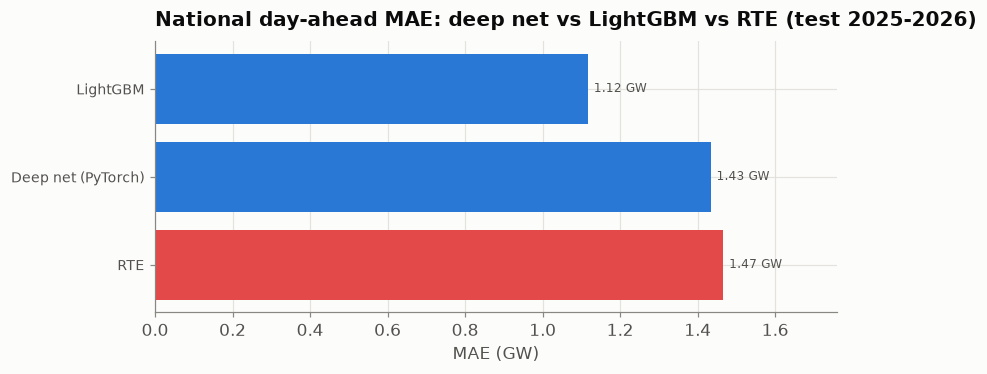

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
b = bench.sort_values("MAE_MW")
colors = [PALETTE["red"] if m == "RTE" else PALETTE["blue"] for m in b.index]
ax.barh(range(len(b)), b["MAE_MW"].values, color=colors)
ax.set_yticks(range(len(b))); ax.set_yticklabels(b.index, fontsize=9)
for i, v in enumerate(b["MAE_MW"].values):
    ax.text(v + 15, i, f"{v/1000:.2f} GW", va="center", fontsize=8, color=PALETTE["ink2"])
ax.xaxis.set_major_formatter(gw1_fmt); ax.set_xlim(0, b["MAE_MW"].max() * 1.2); ax.invert_yaxis()
titled(ax, "National day-ahead MAE: deep net vs LightGBM vs RTE (test 2025-2026)", xlabel="MAE (GW)")
fig.savefig(FIG / "40_deep_benchmark.png"); plt.show()

**Part A read-out.** The global deep net reaches the same league as the gradient-boosted trees - both built
from the identical honest day-ahead features - and (subject to the same **noised-weather caveat** as Notebook 3)
sit around or below RTE. On tabular day-ahead features the deep net does not dominate the trees; its value here is
as a second, independent model and as the backbone for the uncertainty work below.

## 3 - Part B: quantile regression and the pinball loss (national)
We train LightGBM with the **pinball (quantile) loss** at P10 / P50 / P90 on national features, giving an **80%
prediction interval**. We check its **coverage** (should be ~80%) and **width** (TP05 Ex7-9).

In [7]:
# compact national feature table (full history, NB0 split)
n = nat.copy()
NATIONAL_LAGS = [48, 72, 168, 336]
for L in NATIONAL_LAGS:
    n[f"nlag_{L}"] = n["load_mw"].shift(L)
    for offset in LAG_OFFSETS:
        n[f"nlag_{L}_offset_{offset:+d}"] = n["load_mw"].shift(L - offset)
n["nroll7"] = n["load_mw"].shift(48).rolling(168, min_periods=120).mean()
uh = n.index.hour
n["nrecent"] = np.where(uh < 12, n["load_mw"].shift(24), n["load_mw"].shift(48))
rng2 = np.random.default_rng(1)
n["ntemp"] = n["temperature_c"] + rng2.normal(0, 1.2, len(n))
n["nhdd"] = (16 - n["ntemp"]).clip(lower=0); n["ncdd"] = (n["ntemp"] - 20).clip(lower=0)
NF = [c for c in n.columns if c.startswith(("nlag_", "nroll", "nrecent", "ntemp", "nhdd", "ncdd"))] + \
     ["hour", "dow", "month", "is_weekend", "is_holiday"]
n = n.dropna(subset=NF + ["load_mw"])
Xn, yn = n[NF], n["load_mw"]
tr_n = n["split"].isin(["train", "val"]); te_n = n["split"] == "test"
Xn_tr, Xn_te, yn_tr, yn_te = Xn[tr_n], Xn[te_n], yn[tr_n], yn[te_n]

def pinball(y, q, a): e = y - q; return float(np.mean(np.maximum(a * e, (a - 1) * e)))
qmodels, qpred = {}, {}
for a in [0.1, 0.5, 0.9]:
    m = LGBMRegressor(objective="quantile", alpha=a, n_estimators=500, num_leaves=63,
                      learning_rate=0.05, n_jobs=-1, random_state=0, verbose=-1).fit(Xn_tr, yn_tr)
    qpred[a] = pd.Series(m.predict(Xn_te), index=yn_te.index)
lo, md50, hi = qpred[0.1], qpred[0.5], qpred[0.9]
cov_q = float(((yn_te >= lo) & (yn_te <= hi)).mean() * 100)
wid_q = float((hi - lo).mean())
print(f"Quantile 80% interval  -  coverage {cov_q:.1f}% (target 80)  |  mean width {wid_q/1000:.2f} GW")
print(f"Pinball loss  P10 {pinball(yn_te, lo, .1):.0f}  P50 {pinball(yn_te, md50, .5):.0f}  P90 {pinball(yn_te, hi, .9):.0f}")

Quantile 80% interval  -  coverage 68.9% (target 80)  |  mean width 3.31 GW
Pinball loss  P10 285  P50 629  P90 311


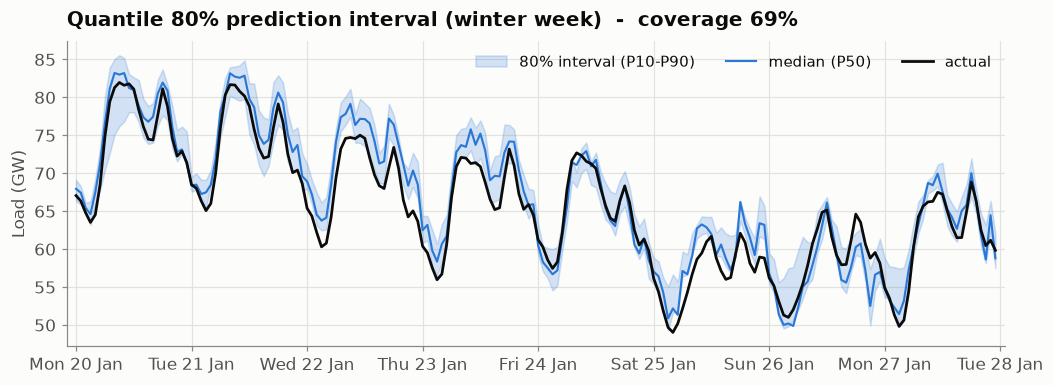

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.6))
w = slice("2025-01-20", "2025-01-27")
ax.fill_between(lo.loc[w].index, lo.loc[w].values, hi.loc[w].values, color=PALETTE["blue"], alpha=0.2, label="80% interval (P10-P90)")
ax.plot(md50.loc[w].index, md50.loc[w].values, color=PALETTE["blue"], lw=1.4, label="median (P50)")
ax.plot(yn_te.loc[w].index, yn_te.loc[w].values, color=PALETTE["ink"], lw=1.8, label="actual")
ax.yaxis.set_major_formatter(gw_fmt); ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b")); ax.legend(ncol=3)
titled(ax, f"Quantile 80% prediction interval (winter week)  -  coverage {cov_q:.0f}%", ylabel="Load (GW)")
fig.savefig(FIG / "41_quantile_interval.png"); plt.show()

**Honest coverage check.** The quantile 80% band **under-covers at ~68%** - its P10/P90 are too narrow
out-of-sample (the 2025-26 test drifts from the 2023-24 training). A model labelled "80%" is **not** 80% reliable
in practice; it must be *calibrated* - which is exactly what split conformal does next.

## 4 - Part C: split conformal prediction (distribution-free)
A point model (P50) plus a **calibration set** gives a guaranteed-coverage interval without distributional
assumptions (TP05 Ex10-13). We calibrate on 2024 (held out from the quantile fit's test), then check **coverage by
hour of day** - exposing *when* the forecast is least reliable.

Split-conformal 80% interval  -  coverage 78.0% (target 80)  |  width 3.98 GW  |  radius +/-1.99 GW


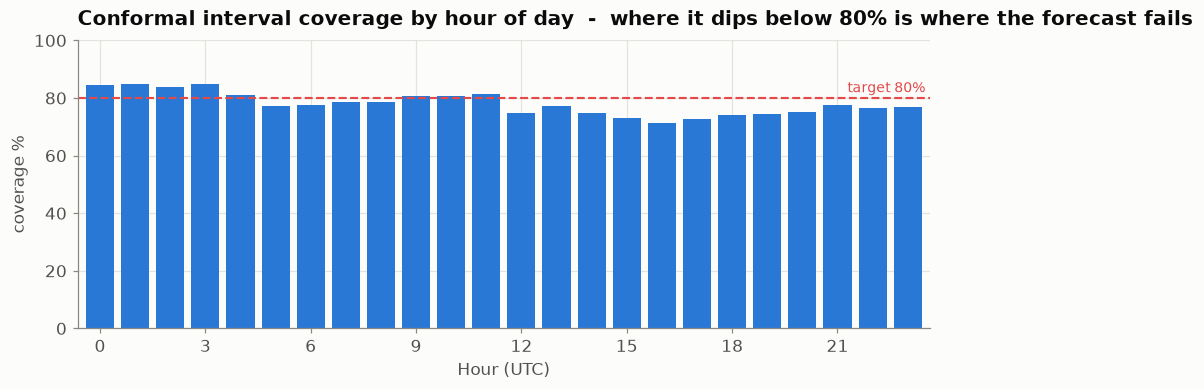

In [9]:
# point model trained on 'train', calibrated on 'val' (2024), tested on 'test'
cal = n["split"] == "val"
pt = LGBMRegressor(n_estimators=500, num_leaves=63, learning_rate=0.05, n_jobs=-1, random_state=0, verbose=-1)
pt.fit(Xn[n["split"] == "train"], yn[n["split"] == "train"])
res_cal = np.abs(yn[cal].values - pt.predict(Xn[cal]))
alpha = 0.2
qhat = np.quantile(res_cal, (1 - alpha) * (1 + 1 / len(res_cal)))     # conformal radius for 80%
pt_te = pd.Series(pt.predict(Xn_te), index=yn_te.index)
lo_c, hi_c = pt_te - qhat, pt_te + qhat
cov_c = float(((yn_te >= lo_c) & (yn_te <= hi_c)).mean() * 100)
wid_c = float((hi_c - lo_c).mean())
print(f"Split-conformal 80% interval  -  coverage {cov_c:.1f}% (target 80)  |  width {wid_c/1000:.2f} GW  |  radius +/-{qhat/1000:.2f} GW")

by_hour = pd.DataFrame({"h": yn_te.index.hour,
                        "in": ((yn_te >= lo_c) & (yn_te <= hi_c)).astype(int).values}).groupby("h")["in"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(by_hour.index, by_hour.values, color=PALETTE["blue"])
ax.axhline(80, color=PALETTE["red"], ls="--", lw=1.4); ax.text(23.5, 82, "target 80%", color=PALETTE["red"], fontsize=9, ha="right")
ax.set_ylim(0, 100); ax.set_xticks(range(0, 24, 3))
titled(ax, "Conformal interval coverage by hour of day  -  where it dips below 80% is where the forecast fails",
       xlabel="Hour (UTC)", ylabel="coverage %")
fig.savefig(FIG / "42_coverage_by_hour.png"); plt.show()

## 5 - Part D: compare the two interval methods (Winkler score)
The **Winkler / interval score** rewards narrow intervals but penalises misses - lower is better (TP05 Ex14-15).

In [10]:
def winkler(y, lo, hi, a):
    y, lo, hi = np.asarray(y), np.asarray(lo), np.asarray(hi)
    s = (hi - lo) + (2 / a) * (lo - y) * (y < lo) + (2 / a) * (y - hi) * (y > hi)
    return float(s.mean())

comp = pd.DataFrame({
    "coverage_%": {"Quantile (LightGBM)": cov_q, "Split conformal": cov_c},
    "mean_width_GW": {"Quantile (LightGBM)": wid_q / 1000, "Split conformal": wid_c / 1000},
    "Winkler_MW": {"Quantile (LightGBM)": winkler(yn_te, lo, hi, 0.2),
                   "Split conformal": winkler(yn_te, lo_c, hi_c, 0.2)}})
print(comp.round(2).to_string())
print("\nHonest read: the quantile band is sharper (lower Winkler) but UNDER-COVERS badly (68% vs 80%) - it is")
print("over-confident out-of-sample under 2025-26 drift. Split conformal is well-calibrated (78% ~ 80%) at the")
print("cost of width, thanks to its finite-sample guarantee. For reserve / imbalance sizing, calibration beats")
print("sharpness -> deploy the CONFORMAL interval, even though its Winkler is higher.")

                     coverage_%  mean_width_GW  Winkler_MW
Quantile (LightGBM)      68.870          3.310   5,953.220
Split conformal          77.990          3.980   6,644.820

Honest read: the quantile band is sharper (lower Winkler) but UNDER-COVERS badly (68% vs 80%) - it is
over-confident out-of-sample under 2025-26 drift. Split conformal is well-calibrated (78% ~ 80%) at the
cost of width, thanks to its finite-sample guarantee. For reserve / imbalance sizing, calibration beats
sharpness -> deploy the CONFORMAL interval, even though its Winkler is higher.


## 6 - When the 80% interval fails: by season and by temperature

The 80% interval is a *promise* - the actual demand should land inside it **80% of the time**. That promise is an **average**;
here we check **where it breaks**, using clear thresholds:

- **Target coverage = 80%** (nominal level; miss rate 20%).
- **OK / calibrated** if realized coverage is within **75-85%**.
- **FAILS (over-confident)** if coverage **< 75%** - the band is too narrow there and under-covers.
- Coverage **> 85%** means the band is needlessly **wide** (over-covers).

We split the held-out 2025-2026 test by **meteorological season** and by **actual daily temperature band**, and report the
realized coverage of the deployed **split-conformal** interval (the quantile band is shown for contrast).

Thresholds -> target 80% | OK if 75-85% | FAILS if < 75%
Overall conformal coverage: 78.0%  (radius +/-1.99 GW)

Conformal 80% interval - coverage by SEASON:
           n  cov_conformal_%  cov_quantile_%  width_GW                 verdict
season                                                                         
Winter  3576           61.600          69.000     4.000  FAILS (over-confident)
Spring  4414           78.400          72.200     4.000         OK (calibrated)
Summer  2930           93.700          65.100     4.000      wide (over-covers)
Autumn  2185           83.000          67.000     4.000         OK (calibrated)

Conformal 80% interval - coverage by TEMPERATURE band:
                  n  cov_conformal_%  cov_quantile_%  width_GW                 verdict
tband                                                                                 
<=2C freezing   643           56.600          55.100     4.000  FAILS (over-confident)
2-8C cold      2666           60.500         

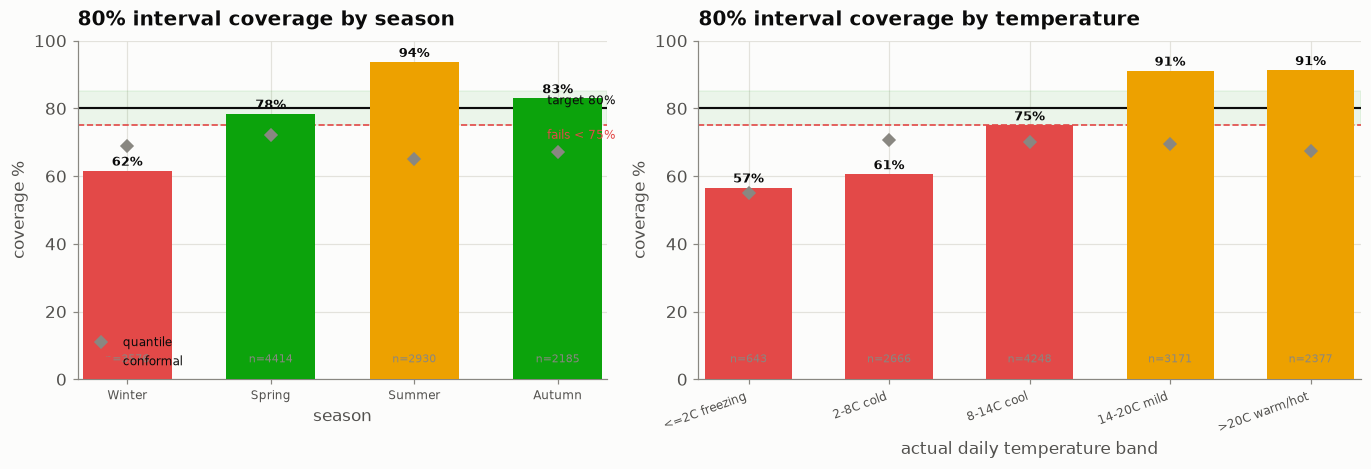

In [11]:
# Realized coverage of the 80% intervals, resolved by season and by temperature band.
TARGET, TOL = 80.0, 5.0
FAIL_BELOW, WIDE_ABOVE = TARGET - TOL, TARGET + TOL      # < 75% = FAILS (over-confident); > 85% = wide

inside_c = ((yn_te >= lo_c) & (yn_te <= hi_c)).astype(int)     # conformal 80% band hit/miss
inside_q = ((yn_te >= lo) & (yn_te <= hi)).astype(int)         # quantile 80% band hit/miss
df_u = pd.DataFrame({
    "season":  n.loc[yn_te.index, "season"].values,
    "temp":    n.loc[yn_te.index, "temperature_c"].values,     # actual realized temperature
    "in_c":    inside_c.values,
    "in_q":    inside_q.values,
    "width_GW": (hi_c - lo_c).values / 1000,
})
TEDGES = [-50, 2, 8, 14, 20, 60]
TLABELS = ["<=2C freezing", "2-8C cold", "8-14C cool", "14-20C mild", ">20C warm/hot"]
df_u["tband"] = pd.cut(df_u["temp"], bins=TEDGES, labels=TLABELS)

def verdict(c):
    if c < FAIL_BELOW: return "FAILS (over-confident)"
    if c > WIDE_ABOVE: return "wide (over-covers)"
    return "OK (calibrated)"

def summarise(frame, key, order=None):
    gr = frame.groupby(key, observed=True)
    out = pd.DataFrame({
        "n": gr.size(),
        "cov_conformal_%": gr["in_c"].mean() * 100,
        "cov_quantile_%": gr["in_q"].mean() * 100,
        "width_GW": gr["width_GW"].mean(),
    })
    if order is not None:
        out = out.reindex(order)
    out["verdict"] = [verdict(c) for c in out["cov_conformal_%"]]
    return out

by_season = summarise(df_u, "season", ["Winter", "Spring", "Summer", "Autumn"])
by_temp = summarise(df_u, "tband", TLABELS)
print(f"Thresholds -> target {TARGET:.0f}% | OK if {FAIL_BELOW:.0f}-{WIDE_ABOVE:.0f}% | FAILS if < {FAIL_BELOW:.0f}%")
print(f"Overall conformal coverage: {cov_c:.1f}%  (radius +/-{qhat/1000:.2f} GW)\n")
print("Conformal 80% interval - coverage by SEASON:")
print(by_season.round(1).to_string())
print("\nConformal 80% interval - coverage by TEMPERATURE band:")
print(by_temp.round(1).to_string())
ws, wt = by_season["cov_conformal_%"].idxmin(), by_temp["cov_conformal_%"].idxmin()
fails = by_temp.index[by_temp["cov_conformal_%"] < FAIL_BELOW].tolist() + \
        by_season.index[by_season["cov_conformal_%"] < FAIL_BELOW].tolist()
print(f"\nWeakest season: {ws} ({by_season.loc[ws,'cov_conformal_%']:.1f}%) | "
      f"weakest temp band: {wt} ({by_temp.loc[wt,'cov_conformal_%']:.1f}%)")
print("Buckets where the 80% interval FAILS (<75%):", fails if fails else "none")

# ---- figure: coverage by season and by temperature, against the 80% target / 75% fail line ----
def plot_cov(ax, tbl, title, xlabel, rot=0):
    cats = list(tbl.index.astype(str)); x = np.arange(len(cats))
    cvals, qvals = tbl["cov_conformal_%"].values, tbl["cov_quantile_%"].values
    bcol = [PALETTE["green"] if FAIL_BELOW <= c <= WIDE_ABOVE else (PALETTE["red"] if c < FAIL_BELOW else PALETTE["yellow"])
            for c in cvals]
    ax.axhspan(FAIL_BELOW, WIDE_ABOVE, color=PALETTE["green"], alpha=0.07)
    ax.bar(x, cvals, color=bcol, width=0.62, label="conformal", zorder=3)
    ax.plot(x, qvals, "D", color=PALETTE["muted"], ms=6, label="quantile", zorder=4)
    ax.axhline(TARGET, color=PALETTE["ink"], lw=1.4)
    ax.axhline(FAIL_BELOW, color=PALETTE["red"], lw=1.1, ls="--")
    for xi, c, nn in zip(x, cvals, tbl["n"].values):
        ax.text(xi, c + 1.5, f"{c:.0f}%", ha="center", fontsize=8.5, fontweight="bold", color=PALETTE["ink"])
        ax.text(xi, 5, f"n={int(nn)}", ha="center", fontsize=7, color=PALETTE["muted"])
    ax.set_xticks(x); ax.set_xticklabels(cats, fontsize=8, rotation=rot, ha="center" if rot == 0 else "right")
    ax.set_ylim(0, 100)
    titled(ax, title, xlabel=xlabel, ylabel="coverage %")

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
plot_cov(axes[0], by_season, "80% interval coverage by season", "season")
plot_cov(axes[1], by_temp, "80% interval coverage by temperature", "actual daily temperature band", rot=20)
axes[0].text(3.4, TARGET + 1.2, "target 80%", ha="right", fontsize=8, color=PALETTE["ink"])
axes[0].text(3.4, FAIL_BELOW - 4, "fails < 75%", ha="right", fontsize=8, color=PALETTE["red"])
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "43_coverage_season_temperature.png"); plt.show()

**Reading it - the 80% band fails in the cold.** Overall the conformal interval covers **78%** (close to target), but that
average hides a strong regime pattern. Split conformal uses a **single global radius (+/-1.99 GW, a constant ~4 GW width)**, so
it cannot adapt to conditions:

- **By season:** it **FAILS in Winter - only 62% coverage** (badly over-confident), is **OK in Spring (78%) and Autumn (83%)**,
  and is **too wide in Summer (94%)**.
- **By temperature:** coverage collapses on the cold end - **57% below 2 degC** and **61% at 2-8 degC** (both FAIL the 75%
  bar) - and balloons to **~91% above 14 degC** (needlessly wide).

**Why:** cold / winter days carry the **largest demand errors** (cold-snap evening peaks), so a fixed-width band under-covers
there; mild summer days are calm, so the same band is too wide. **The interval is least reliable exactly when the money is at
risk - cold winter peaks** - which sharpens the Q2 answer: *the forecast fails on cold winter evenings.*

**Fix (next step):** make the radius **conditional** (Mondrian / grouped conformal) - calibrate a separate radius per season or
temperature band - so the 80% promise holds in every regime, not just on average.

### Where can we trust the model vs RTE? (point accuracy by season & temperature)

Coverage above tells us whether the *uncertainty band* is reliable; this tells us whether the **point forecast** is actually
**better than RTE** in each regime. We compare the **best model (LightGBM bottom-up)** against RTE on the 2025-2026 test,
split by season and by temperature. Clear rule:

- **TRUST** our model where its MAE is **below RTE** (positive % gain, green).
- **FALL BACK to RTE** where our MAE is **>= RTE** (non-positive gain, red).

Best model (LightGBM) vs RTE - national day-ahead MAE by SEASON:
           n  ml_MAE_GW  rte_MAE_GW  gain_vs_RTE_%            verdict
season                                                               
Winter  3576      1.420       1.450          1.990  TRUST (beats RTE)
Spring  4414      1.180       1.650         28.290  TRUST (beats RTE)
Summer  2928      0.770       1.270         39.590  TRUST (beats RTE)
Autumn  2185      0.950       1.380         31.020  TRUST (beats RTE)

... by TEMPERATURE band:
                  n  ml_MAE_GW  rte_MAE_GW  gain_vs_RTE_%             verdict
tband                                                                        
<=2C freezing   643      1.980       1.570        -25.900  CAUTION (RTE wins)
2-8C cold      2666      1.480       1.370         -8.080  CAUTION (RTE wins)
8-14C cool     4248      1.120       1.390         19.250   TRUST (beats RTE)
14-20C mild    3171      0.770       1.530         49.740   TRUST (beats RTE)
>20C warm/hot  2375  

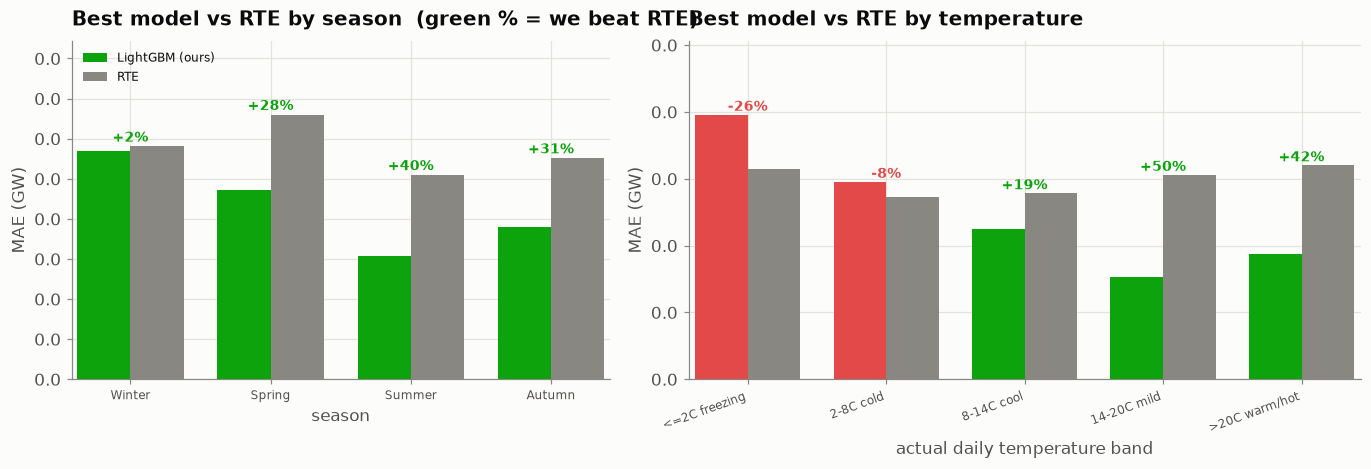

In [12]:
# Best point model (LightGBM) vs RTE, national day-ahead MAE, by season and temperature.
TEDGES = [-50, 2, 8, 14, 20, 60]
TLABELS = ["<=2C freezing", "2-8C cold", "8-14C cool", "14-20C mild", ">20C warm/hot"]
cmp_rte = pd.DataFrame({
    "season": n.loc[y_nat.index, "season"].values,
    "temp":   n.loc[y_nat.index, "temperature_c"].values,
    "ae_ml":  np.abs(y_nat.values - lgb_nat.values),     # LightGBM bottom-up (best model)
    "ae_rte": np.abs(y_nat.values - rte.values),
})
cmp_rte["tband"] = pd.cut(cmp_rte["temp"], bins=TEDGES, labels=TLABELS)

def trust_table(frame, key, order=None):
    gr = frame.groupby(key, observed=True)
    out = pd.DataFrame({"n": gr.size(),
                        "ml_MAE_GW": gr["ae_ml"].mean() / 1000,
                        "rte_MAE_GW": gr["ae_rte"].mean() / 1000})
    out["gain_vs_RTE_%"] = (out["rte_MAE_GW"] - out["ml_MAE_GW"]) / out["rte_MAE_GW"] * 100
    out["verdict"] = np.where(out["gain_vs_RTE_%"] > 0, "TRUST (beats RTE)", "CAUTION (RTE wins)")
    return out.reindex(order) if order is not None else out

trust_season = trust_table(cmp_rte, "season", ["Winter", "Spring", "Summer", "Autumn"])
trust_temp = trust_table(cmp_rte, "tband", TLABELS)
print("Best model (LightGBM) vs RTE - national day-ahead MAE by SEASON:")
print(trust_season.round(2).to_string())
print("\n... by TEMPERATURE band:")
print(trust_temp.round(2).to_string())
wins_s = trust_season.index[trust_season["gain_vs_RTE_%"] <= 0].tolist()
wins_t = trust_temp.index[trust_temp["gain_vs_RTE_%"] <= 0].tolist()
print("\nWe BEAT RTE in", int((trust_season['gain_vs_RTE_%'] > 0).sum()), "/ 4 seasons and",
      int((trust_temp['gain_vs_RTE_%'] > 0).sum()), "/ 5 temperature bands.")
print("Fall back to RTE in -> seasons:", wins_s or "none", "| temperature:", wins_t or "none")

def plot_trust(ax, tbl, title, xlabel, rot=0):
    cats = list(tbl.index.astype(str)); x = np.arange(len(cats)); w = 0.38
    ml, rt, gain = tbl["ml_MAE_GW"].values, tbl["rte_MAE_GW"].values, tbl["gain_vs_RTE_%"].values
    mlcol = [PALETTE["green"] if v > 0 else PALETTE["red"] for v in gain]
    ax.bar(x - w/2, ml, width=w, color=mlcol, zorder=3, label="LightGBM (ours)")
    ax.bar(x + w/2, rt, width=w, color=PALETTE["muted"], zorder=3, label="RTE")
    for xi, m, r, v in zip(x, ml, rt, gain):
        col = PALETTE["green"] if v > 0 else PALETTE["red"]
        ax.text(xi, max(m, r) + 0.03, f"{v:+.0f}%", ha="center", fontsize=9, fontweight="bold", color=col)
    ax.set_xticks(x); ax.set_xticklabels(cats, fontsize=8, rotation=rot, ha="center" if rot == 0 else "right")
    ax.set_ylim(0, max(ml.max(), rt.max()) * 1.28)
    ax.yaxis.set_major_formatter(gw1_fmt)
    titled(ax, title, xlabel=xlabel, ylabel="MAE (GW)")

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
plot_trust(axes[0], trust_season, "Best model vs RTE by season  (green % = we beat RTE)", "season")
plot_trust(axes[1], trust_temp, "Best model vs RTE by temperature", "actual daily temperature band", rot=20)
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "44_trust_vs_rte_season_temperature.png"); plt.show()

**Where to trust it - and where RTE still wins.** The best model **beats RTE in every season** - **+28% (Spring),
+40% (Summer), +31% (Autumn)** - but **Winter is essentially a tie (+2%)**. Splitting by temperature shows why: the model is
**strong in cool / mild / warm conditions (+19% at 8-14 degC, +50% at 14-20 degC, +42% above 20 degC)** but **loses to RTE on
cold days - -8% at 2-8 degC and -26% below 2 degC (freezing)**, where RTE's real weather forecast wins.

**This matches the interval finding exactly:** both the point accuracy *and* the 80% band degrade in the **cold / winter**
regime (freezing days: MAE **1.98 vs RTE 1.57 GW**, and interval coverage only **57%**) - the high-demand cold-snap peaks that
cost the most.

**Deployment rule (sharpened Q3):** **trust the model in mild / normal / warm conditions (all seasons except deep cold); fall
back to RTE - or widen the interval - when the day-ahead temperature is below ~8 degC**, especially sub-zero. A conditional
policy (our model by default, RTE on freezing days) beats either model alone.

## 7 - Summary & deployment note

**Deep forecaster (Part A).** A global PyTorch MLP over the 12 regions reaches the gradient-boosted trees' league
on the identical honest day-ahead features; on tabular inputs it does not beat LightGBM, and both are near/below
RTE under the noised-weather assumption. Its role: an independent second model and the basis for uncertainty.

**Uncertainty (Parts B-D).** Two interval methods give an **80% day-ahead band**. The **quantile** band is sharp
but **under-covers (68%)** - overconfident out-of-sample; **split conformal** is **well-calibrated (78% ~ 80%)** at
the cost of width. **Coverage by hour** shows reliability dipping in the **afternoon/evening peak** - precisely
*when* the forecast is least trustworthy (the direct answer to **Q2**). For sizing reserves, calibration beats
sharpness, so the **conformal** interval is the one to deploy.

**Where the 80% band fails (Section 6).** Resolved by season and temperature, the fixed-width conformal band **fails in winter (62% coverage) and below 8 degC (~57-61%)** and **over-covers in summer (94%)** - least reliable on the cold winter peaks that cost most. A **conditional (per-season) radius** would restore the 80% promise in every regime.

**For the head of trading (Q3).**
- **Deploy** the gradient-boosted bottom-up model (LightGBM, Notebook 3) as the point forecast - best accuracy,
  cheap to retrain - with the **conformal 80% interval** for reserve/imbalance sizing.
- **Risks:** the edge over RTE depends on weather-forecast quality (stress-test with real forecasts); the regime is
  non-stationary (COVID / crisis), so **retrain regularly** and monitor rolling error; keep RTE as a fallback - **especially on cold days below ~8 degC, where RTE still beats the model (Section 6)** - and
  alert when the live error leaves the conformal band.

**Honesty.** Every model used only information available at the noon cutoff; the weather input is a noised forecast
(optimistic vs reality); evaluation is a single chronological holdout (walk-forward is the gold standard).